# corrector_06 - Retrain, calibrate, check and report (role B, task items 2 to 8)

Needs: `corrector_05_clean_corpus.ipynb` already run (the cleaned `data/corpus/`), and role A's
`outputs/ocr_out.jsonl`. **T4 GPU** runtime. Needs the `GITHUB_TOKEN` secret.

Every stage saves its result in `outputs/corrector_stages/`. If Colab stops, run all again:
finished stages are read back instead of computed again (put a stage name in `FORCE` to redo it).

| Stage | Task item | Output |
|---|---|---|
| ngram | 6 (retrain) | `checkpoints/corrector/ngram.pkl.gz`, `viterbi.json` |
| calibration_ngram | 5 | temperatures of the frequency and bigram levels |
| tagger_seeds | 6, 8 | `tagger_seed*.pt`, best one as `tagger.pt` (calibrated) |
| folds | 8 | 5 contiguous folds for frequency and bigram |
| models_report | 3 | file names, sizes, loading times |
| ocr_val | 2, 4, 5 | contract check on the 636 OCR val lines, ECE, default level |
| reference | 7 | `outputs/corrector_reference_check.json` |
| test_once | 8 | the corpus test.txt, scored once |
| (last cell) | 8 | `outputs/corrector_eval.json` |

Only the val split of UIT-HWDB is used. Its 201 test lines are never touched here.

In [1]:
from google.colab import drive, userdata

drive.mount("/content/drive")

token = userdata.get("GITHUB_TOKEN").strip()
BRANCH = "b/corrector"  # change to "main" after the code is merged
!rm -rf /content/repo
!git clone -q -b {BRANCH} https://{token}@github.com/wickyhien18/Vietnamese-Handwriting-OCR.git /content/repo
%cd /content/repo
!pip install -q -r requirements.txt

DRIVE_ROOT = "/content/drive/MyDrive/Vietnamese-Handwriting-OCR"
DATA_DIR = f"{DRIVE_ROOT}/data"
CKPT_DIR = f"{DRIVE_ROOT}/checkpoints"
OUT_DIR = f"{DRIVE_ROOT}/outputs"

!pip install -q nltk hmmlearn

Mounted at /content/drive
/content/repo


In [2]:
!python -m unittest discover -s tests -t . 2>&1 | tail -6

IndexError: index out of range in self

----------------------------------------------------------------------
Ran 206 tests in 20.627s

FAILED (errors=1)


## Settings

In [3]:
import itertools, json, os, time
import numpy as np
import torch

from src.corrector.experiments import (NGRAM_HYPERPARAMETERS as HP, collect_level_logits,
                                       confidence_pairs, contract_violations, mean_std, ngram_folds,
                                       read_lines, spread_sample, summarize_runs, train_ngram)
from src.corrector.evaluate import evaluate
from src.corrector.noise import NoiseConfig, make_pairs
from src.corrector.ocr_adapt import confidence_pairs_ocr, evaluate_on_ocr, ocr_lines

CORPUS_DIR = f"{DATA_DIR}/corpus"
MODEL_DIR = f"{CKPT_DIR}/corrector"
STAGE_DIR = f"{OUT_DIR}/corrector_stages"
N_NGRAM_TRAIN = 1_000_000       # sentences counted for the shipped n-gram model
N_CAL = 5_000                   # corpus val sentences: temperature fitting, tagger choice, ECE
N_EVAL = 2_000                  # sentences per accuracy measurement
N_FOLD_SENTENCES = 1_000_000    # sentences split into the 5 folds
N_FOLDS = 5
TAGGER_SEEDS = [0, 1, 2, 3, 4]
TAGGER_SENTENCES = 300_000      # per seed (lowered from 600k x 3 epochs to keep 5 seeds affordable)
TAGGER_EPOCHS = 2
TAGGER_LR = 5e-4
TAGGER_CONFIG = {"d_model": 256, "n_heads": 4, "n_layers": 4, "d_ff": 1024, "max_len": 64, "dropout": 0.1}
N_TEST = 5_000                  # corpus test.txt sentences, scored once at the end
FORCE = set()                   # for example {"ocr_val"} to compute a stage again

device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(STAGE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

with open(f"{CORPUS_DIR}/stats.json", encoding="utf-8") as f:
    corpus_stats = json.load(f)
assert corpus_stats.get("max_syllables") == 40, "run corrector_05_clean_corpus.ipynb first"

val_sentences = read_lines(f"{CORPUS_DIR}/val.txt", 0, N_CAL)
cal_pairs = list(make_pairs(val_sentences, seed=HP["noise_seed"]))   # same noise in every run
eval_pairs = cal_pairs[:N_EVAL]
with open(f"{OUT_DIR}/ocr_out.jsonl", encoding="utf-8") as f:
    ocr_val = ocr_lines([json.loads(line) for line in f if line.strip()], split="val")
print("device:", device, "| corpus:", corpus_stats["sentences"], "| OCR val lines:", len(ocr_val))


def stage(name, compute):
    path = f"{STAGE_DIR}/{name}.json"
    if os.path.exists(path) and name not in FORCE:
        print(f"[{name}] read back from {path}")
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    start = time.time()
    result = compute()
    result["seconds"] = round(time.time() - start, 1)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(result, f, ensure_ascii=False, indent=1)
    print(f"[{name}] done in {result['seconds']:.0f} s, saved {path}")
    return result


def update_viterbi_json(**values):
    path = f"{MODEL_DIR}/viterbi.json"
    settings = json.load(open(path, encoding="utf-8")) if os.path.exists(path) else {}
    settings.update(values)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(settings, f, indent=1)

device: cpu | corpus: {'train': 1469903, 'val': 15122, 'test': 15028} | OCR val lines: 636


## Stage ngram: retrain the n-gram model on the cleaned corpus (item 6)

In [4]:
from src.corrector.ngram import NgramModel

def run_ngram():
    sentences = read_lines(f"{CORPUS_DIR}/train.txt", 0, N_NGRAM_TRAIN)
    model, p_same = train_ngram(sentences, HP)
    model.save(f"{MODEL_DIR}/ngram.pkl.gz")
    update_viterbi_json(p_same=p_same, k=HP["k"], temperature=1.0, temperature_frequency=1.0)
    return {"sentences": len(sentences), "words": model.total_words, "syllables": len(model.unigram),
            "plain_keys": len(model.forms), "bigrams_after_pruning": len(model.bigram),
            "p_same": p_same, "hyperparameters": HP}

ngram_info = stage("ngram", run_ngram)
ngram = NgramModel.load(f"{MODEL_DIR}/ngram.pkl.gz")
print(json.dumps({k: v for k, v in ngram_info.items() if k != "hyperparameters"}, indent=1))

[ngram] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/ngram.json
{
 "sentences": 1000000,
 "words": 19545247,
 "syllables": 152173,
 "plain_keys": 142696,
 "bigrams_after_pruning": 833904,
 "p_same": 0.6151017982950756,
 "seconds": 106.2
}


## Stage calibration_ngram: temperature scaling for the frequency and bigram levels (item 5)

In [5]:
from src.corrector.calibration import calibration_report, fit_temperature
from src.corrector.correctors import FrequencyCorrector, ViterbiCorrector
from src.corrector.viterbi import Emission

def run_calibration_ngram():
    p_same = json.load(open(f"{MODEL_DIR}/viterbi.json"))["p_same"]
    result = {}
    for level, corrector in (("frequency", FrequencyCorrector(ngram, HP["k"])),
                             ("bigram", ViterbiCorrector(ngram, Emission(p_same), HP["k"]))):
        logits, targets = collect_level_logits(corrector, cal_pairs, HP["k"] + 1)
        t = fit_temperature(logits, targets)
        result[level] = calibration_report(logits, targets, t)
        result[level]["positions"] = int(len(targets))
    update_viterbi_json(temperature=result["bigram"]["temperature"],
                        temperature_frequency=result["frequency"]["temperature"])
    return result

calibration_ngram = stage("calibration_ngram", run_calibration_ngram)
print(json.dumps(calibration_ngram, indent=1))

[calibration_ngram] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/calibration_ngram.json
{
 "frequency": {
  "accuracy": 0.7233079503700942,
  "temperature": 0.9890990724121609,
  "nll_raw": 0.7369120381746128,
  "ece_raw": 0.0028552366732588087,
  "nll_scaled": 0.7368745254341595,
  "ece_scaled": 0.0031321025822630883,
  "positions": 93895
 },
 "bigram": {
  "accuracy": 0.9536737817841653,
  "temperature": 1.1842457941598419,
  "nll_raw": 0.1709083003623751,
  "ece_raw": 0.006312964111934887,
  "nll_scaled": 0.16682182640699705,
  "ece_scaled": 0.005831872278306605,
  "positions": 94072
 },
 "seconds": 17.2
}


## Stage tagger_seeds: train the transformer with 5 seeds, keep the best on val (items 6 and 8)

In [6]:
from torch.utils.data import DataLoader
from src.corrector.tagger import (DiacriticTagger, NoisySentences, TransformerCorrector, collate,
                                  collect_logits, load_checkpoint, make_scheduler, save_checkpoint,
                                  train_epoch)
from src.corrector.tagger_data import TaggerVocab

vocab = TaggerVocab.from_ngram(ngram, min_count=3, k=HP["k"])
K_MAX = vocab.k + 1
cal_data = NoisySentences(val_sentences, vocab, NoiseConfig(), seed=HP["noise_seed"],
                          max_len=TAGGER_CONFIG["max_len"], fixed_noise=True)
cal_loader = DataLoader(cal_data, batch_size=256, collate_fn=collate, num_workers=2)

def train_one_seed(seed):
    path = f"{STAGE_DIR}/tagger_seed{seed}.json"
    if os.path.exists(path) and "tagger_seeds" not in FORCE:
        return json.load(open(path))
    torch.manual_seed(seed)
    sentences = read_lines(f"{CORPUS_DIR}/train.txt", 0, TAGGER_SENTENCES)
    data = NoisySentences(sentences, vocab, NoiseConfig(), seed=seed, max_len=TAGGER_CONFIG["max_len"])
    loader = DataLoader(data, batch_size=128, shuffle=True, collate_fn=collate, num_workers=2,
                        generator=torch.Generator().manual_seed(seed))
    model = DiacriticTagger(len(vocab.forms), len(vocab.keys), **TAGGER_CONFIG).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=TAGGER_LR, weight_decay=0.01)
    scheduler = make_scheduler(optimizer, TAGGER_EPOCHS * len(loader), warmup_steps=1000)
    start = time.time()
    for epoch in range(TAGGER_EPOCHS):
        data.epoch = epoch
        loss = train_epoch(model, loader, optimizer, scheduler, device, log_every=0)
        print(f"  seed {seed} epoch {epoch + 1}: loss {loss:.4f}")
    train_seconds = time.time() - start
    save_checkpoint(f"{MODEL_DIR}/tagger_seed{seed}.pt", model, vocab, TAGGER_CONFIG, temperature=1.0)
    logits, targets = collect_logits(model, cal_loader, device, K_MAX)
    result = evaluate(TransformerCorrector(model, vocab, 1.0, device), eval_pairs, ngram)
    result.update(seed=seed, val_candidate_accuracy=float((logits.argmax(1) == targets).mean()),
                  train_seconds=round(train_seconds, 1), final_loss=loss)
    json.dump(result, open(path, "w"), indent=1)
    print(f"seed {seed}: syllable accuracy {result['all']:.4f}, {train_seconds / 60:.1f} min")
    return result

def run_tagger_seeds():
    runs = [train_one_seed(seed) for seed in TAGGER_SEEDS]
    best = max(runs, key=lambda r: r["val_candidate_accuracy"])
    chosen = load_checkpoint(f"{MODEL_DIR}/tagger_seed{best['seed']}.pt", device)
    logits, targets = collect_logits(chosen.model, cal_loader, device, K_MAX)
    multi = np.isfinite(logits).sum(axis=1) >= 2
    t = fit_temperature(logits[multi], targets[multi])
    save_checkpoint(f"{MODEL_DIR}/tagger.pt", chosen.model, vocab, TAGGER_CONFIG, temperature=t)
    hp = {"config": TAGGER_CONFIG, "sentences": TAGGER_SENTENCES, "epochs": TAGGER_EPOCHS, "lr": TAGGER_LR,
          "batch": 128, "noise": NoiseConfig().__dict__, "vocab_min_count": 3}
    summary = summarize_runs(runs, "seed", hp)
    summary.update(chosen_seed=best["seed"], calibration=calibration_report(logits[multi], targets[multi], t),
                   minutes_per_run=round(mean_std([r["train_seconds"] for r in runs])[0] / 60, 1))
    return summary

tagger_seeds = stage("tagger_seeds", run_tagger_seeds)
print({m: tagger_seeds[m] for m in ("all", "ambiguous")}, "chosen seed:", tagger_seeds["chosen_seed"])

[tagger_seeds] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/tagger_seeds.json
{'all': {'mean': 0.9204042542466858, 'std': 0.0008338689178105896}, 'ambiguous': {'mean': 0.9180598229995536, 'std': 0.0008688844486695432}} chosen seed: 1


## Stage folds: frequency table and bigram + Viterbi on 5 contiguous folds (item 8)

In [7]:
def run_folds():
    sentences = read_lines(f"{CORPUS_DIR}/train.txt", 0, N_FOLD_SENTENCES)
    return ngram_folds(sentences, N_FOLDS, N_EVAL)

folds = stage("folds", run_folds)
for level in ("frequency", "bigram"):
    print(level, {m: folds[level][m] for m in ("all", "ambiguous")})

[folds] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/folds.json
frequency {'all': {'mean': 0.7277966753672913, 'std': 0.0038983124134601447}, 'ambiguous': {'mean': 0.7150099269945691, 'std': 0.0027358039968840816}}
bigram {'all': {'mean': 0.9474260084529845, 'std': 0.002130346688102661}, 'ambiguous': {'mean': 0.9458707264501329, 'std': 0.0021496691177427243}}


## Stage models_report: model files, sizes and loading time (item 3)

In [8]:
from src.corrector import api

def run_models_report():
    files = {name: round(os.path.getsize(f"{MODEL_DIR}/{name}") / 1e6, 2)
             for name in sorted(os.listdir(MODEL_DIR)) if os.path.isfile(f"{MODEL_DIR}/{name}")}
    load_seconds = {}
    for level in ("frequency", "bigram", "tagger"):
        api._cache.clear()
        start = time.time()
        fn = api.get_corrector(level, MODEL_DIR, device)
        fn("nhieu ban doc da bay to")
        load_seconds[level] = round(time.time() - start, 2)
    return {"folder": MODEL_DIR, "env_variable": api.CKPT_ENV, "files_mb": files,
            "load_and_first_call_seconds": load_seconds}

models_report = stage("models_report", run_models_report)
print(json.dumps(models_report, indent=1))

[models_report] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/models_report.json
{
 "folder": "/content/drive/MyDrive/Vietnamese-Handwriting-OCR/checkpoints/corrector",
 "env_variable": "CORRECTOR_CKPT_DIR",
 "files_mb": {
  "ngram.pkl.gz": 6.62,
  "tagger.pt": 147.63,
  "tagger_seed0.pt": 147.63,
  "tagger_seed1.pt": 147.63,
  "tagger_seed2.pt": 147.63,
  "tagger_seed3.pt": 147.63,
  "tagger_seed4.pt": 147.63,
  "viterbi.json": 0.0
 },
 "load_and_first_call_seconds": {
  "frequency": 1.52,
  "bigram": 1.97,
  "tagger": 0.76
 },
 "seconds": 4.3
}


## Stage ocr_val: contract check, ECE and the default level on the 636 real OCR val lines (items 2, 4, 5)

ECE: 10 bins of equal width over [0, 1], each bin weighted by its share of syllables.
On the corpus val, every syllable counts; on the OCR val, the syllables matched to a label syllable
by alignment (option 2 of the evaluation notebook).

In [9]:
from src.corrector.calibration import expected_calibration_error

def ece_both(corrector, conf_fn, data):
    fitted = corrector.temperature
    conf_t, right_t = conf_fn(corrector, data)
    corrector.temperature = 1.0
    conf_1, right_1 = conf_fn(corrector, data)
    corrector.temperature = fitted
    return {"ece_raw": expected_calibration_error(conf_1, right_1),
            "ece_scaled": expected_calibration_error(conf_t, right_t),
            "temperature": fitted, "syllables": len(conf_t)}, conf_t

def run_ocr_val():
    result = {"levels": {}, "ece_bins": 10, "ece_weights": "share of syllables in the bin"}
    conf_store = {}
    for level in ("identity", "frequency", "bigram", "tagger"):
        api._cache.clear()
        corrector = api.build_corrector(level, MODEL_DIR, device)
        row = {"contract": contract_violations(corrector.correct, [ocr for _, ocr in ocr_val])}
        r = evaluate_on_ocr(corrector, ocr_val, tau=0.0)
        r["examples"] = {k: v[:10] for k, v in r["examples"].items()}
        row["ocr_val"] = r
        if level != "identity":
            row["ece_corpus_val"], _ = ece_both(corrector, confidence_pairs, eval_pairs)
            row["ece_ocr_val"], conf_store[level] = ece_both(corrector, confidence_pairs_ocr, ocr_val)
        result["levels"][level] = row
        print(f"{level:<9} violations {row['contract']['violations']}  "
              f"CER {r['cer_before']:.4f} -> {r['cer_after']:.4f}  broken rate {r['broken_rate']:.4f}")
    np.savez(f"{STAGE_DIR}/ocr_val_conf.npz", **{k: np.array(v) for k, v in conf_store.items()})
    levels = ("frequency", "bigram", "tagger")
    best = min(levels, key=lambda l: result["levels"][l]["ocr_val"]["cer_after"])
    choice = {"level": best,
              "chosen_on": "UIT-HWDB val (636 OCR lines), lowest CER when every suggestion is accepted (tau = 0)",
              "cer_after": {l: result["levels"][l]["ocr_val"]["cer_after"] for l in levels},
              "cer_without_correction": result["levels"]["identity"]["ocr_val"]["cer_before"],
              "date": time.strftime("%Y-%m-%d")}
    with open(f"{MODEL_DIR}/default_level.json", "w", encoding="utf-8") as f:
        json.dump(choice, f, indent=1)
    result["default_level"] = choice
    return result

ocr_val_result = stage("ocr_val", run_ocr_val)
print("default level:", json.dumps(ocr_val_result["default_level"], indent=1))

[ocr_val] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/ocr_val.json
default level: {
 "level": "tagger",
 "chosen_on": "UIT-HWDB val (636 OCR lines), lowest CER when every suggestion is accepted (tau = 0)",
 "cer_after": {
  "frequency": 0.17853957509090493,
  "bigram": 0.15004459487273308,
  "tagger": 0.13721499302490453
 },
 "cer_without_correction": 0.12271594209527294,
 "date": "2026-11-22"
}


### Distribution of the confidences on the OCR val (item 5)

frequency share of syllables with conf >= 0.95: 29.2%, below 0.5: 17.1%
bigram    share of syllables with conf >= 0.95: 60.8%, below 0.5: 6.5%
tagger    share of syllables with conf >= 0.95: 75.1%, below 0.5: 3.7%


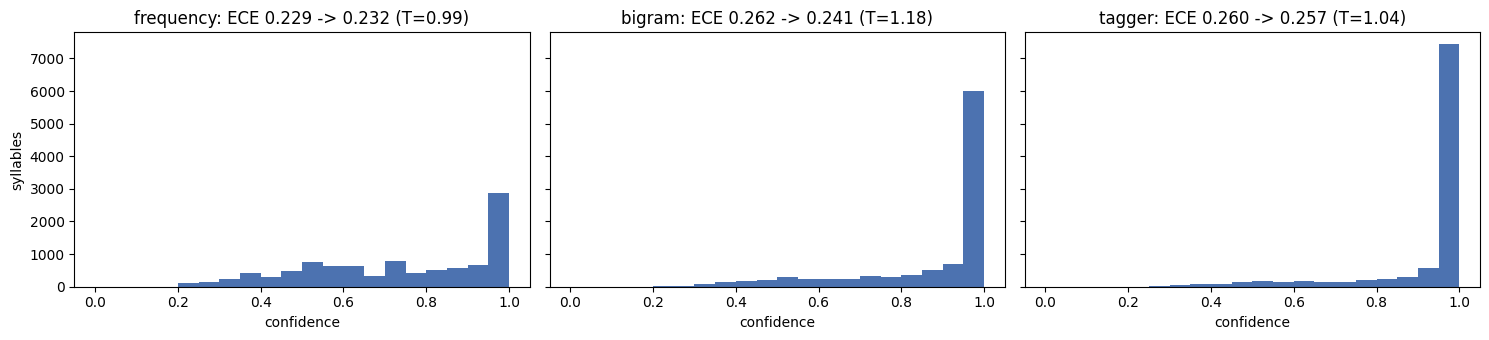

In [10]:
import matplotlib.pyplot as plt

conf_store = np.load(f"{STAGE_DIR}/ocr_val_conf.npz")
fig, axes = plt.subplots(1, len(conf_store.files), figsize=(5 * len(conf_store.files), 3.5), sharey=True)
for ax, level in zip(np.atleast_1d(axes), conf_store.files):
    values = conf_store[level]
    ax.hist(values, bins=20, range=(0, 1), color="#4C72B0")
    ece = ocr_val_result["levels"][level]["ece_ocr_val"]
    ax.set_title(f"{level}: ECE {ece['ece_raw']:.3f} -> {ece['ece_scaled']:.3f} (T={ece['temperature']:.2f})")
    ax.set_xlabel("confidence")
    print(f"{level:<9} share of syllables with conf >= 0.95: {(values >= 0.95).mean():.1%}, "
          f"below 0.5: {(values < 0.5).mean():.1%}")
np.atleast_1d(axes)[0].set_ylabel("syllables")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/corrector_conf_hist.png", dpi=150)
plt.show()

## Stage reference: hand-written parts against standard libraries (item 7)

In [11]:
from src.corrector import reference_check as rc

def run_reference():
    p_same = json.load(open(f"{MODEL_DIR}/viterbi.json"))["p_same"]
    checks = {
        "ngram_vs_nltk": lambda: rc.compare_ngram_with_nltk(val_sentences[:2000], HP["interpolation"]),
        "viterbi_vs_brute_force": lambda: rc.compare_viterbi_brute_force(
            ngram, Emission(p_same), read_lines(f"{CORPUS_DIR}/val.txt", 0, 13_000), HP["k"]),
        "viterbi_vs_hmmlearn": lambda: rc.compare_viterbi_hmmlearn(trials=50),
        "attention_vs_torch": lambda: rc.compare_attention(d_model=64, n_heads=4),
    }
    result = {"tagger_declaration": rc.TAGGER_DECLARATION}
    for name, fn in checks.items():
        try:
            result[name] = fn()
        except Exception as error:  # record the problem, keep the other checks
            result[name] = {"error": repr(error)}
        print(name, result[name])
    with open(f"{OUT_DIR}/corrector_reference_check.json", "w", encoding="utf-8") as f:
        json.dump(result, f, ensure_ascii=False, indent=1)
    return result

reference = stage("reference", run_reference)

[reference] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/reference.json


## Stage test_once: the corpus test.txt, scored once (item 8)

All settings above were chosen on val. This is the corpus test file (not the 201 UIT-HWDB test lines).
A second run reads the saved result and never scores test again.

In [12]:
def run_test_once():
    test_pairs = list(make_pairs(spread_sample(read_lines(f"{CORPUS_DIR}/test.txt"), N_TEST),
                                 seed=HP["noise_seed"]))
    result = {"sentences": len(test_pairs)}
    for level in ("frequency", "bigram", "tagger"):
        corrector = api.build_corrector(level, MODEL_DIR, device)
        result[level] = evaluate(corrector, test_pairs, ngram)
        print(level, {m: round(result[level][m], 4) for m in ("all", "ambiguous", "broken")})
    return result

test_once = stage("test_once", run_test_once)

[test_once] read back from /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_stages/test_once.json


## outputs/corrector_eval.json

In [13]:
levels = {
    "frequency": {k: folds["frequency"][k] for k in ("all", "ambiguous", "noisy", "broken", "n_runs", "seeds", "std", "runs_are", "hyperparameters")},
    "bigram": {k: folds["bigram"][k] for k in ("all", "ambiguous", "noisy", "broken", "n_runs", "seeds", "std", "runs_are", "hyperparameters")},
    "tagger": {k: tagger_seeds[k] for k in ("all", "ambiguous", "noisy", "broken", "n_runs", "seeds", "std", "runs_are", "hyperparameters", "chosen_seed", "minutes_per_run")},
}
for level in levels:
    levels[level]["temperature"] = (calibration_ngram[level]["temperature"] if level != "tagger"
                                    else tagger_seeds["calibration"]["temperature"])
    levels[level]["ece_corpus_val"] = ocr_val_result["levels"][level]["ece_corpus_val"]
    levels[level]["ece_ocr_val"] = ocr_val_result["levels"][level]["ece_ocr_val"]
    levels[level]["contract_violations_ocr_val"] = ocr_val_result["levels"][level]["contract"]["violations"]
    o = ocr_val_result["levels"][level]["ocr_val"]
    levels[level]["ocr_val_tau0"] = {k: o[k] for k in ("cer_before", "cer_after", "wer_before", "wer_after",
                                                       "broken_rate", "fixed_of_fixable", "net_fixed", "counts")}
    levels[level]["corpus_test_once"] = test_once[level]

report = {
    "note": "Accuracy on the corpus is not the result of the project; role C measures fixed/broken and the tau sweep on the real OCR val.",
    "corpus": corpus_stats,
    "noise": NoiseConfig().__dict__,
    "ambiguous_means": "a syllable whose form without diacritics has 2 or more accented forms in the training text",
    "std": "sample standard deviation (ddof=1)",
    "levels": levels,
    "default_level": ocr_val_result["default_level"],
    "ocr_val_lines": len(ocr_val),
    "ece": {"bins": 10, "weights": "share of syllables in the bin"},
    "models_report": models_report,
}
with open(f"{OUT_DIR}/corrector_eval.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=1)
print("saved", f"{OUT_DIR}/corrector_eval.json")
for level, r in levels.items():
    print(f"{level:<9} corpus all {r['all']['mean']:.4f} ± {r['all']['std']:.4f}  "
          f"ambiguous {r['ambiguous']['mean']:.4f} ± {r['ambiguous']['std']:.4f}  "
          f"OCR val CER {r['ocr_val_tau0']['cer_before']:.4f} -> {r['ocr_val_tau0']['cer_after']:.4f}")

saved /content/drive/MyDrive/Vietnamese-Handwriting-OCR/outputs/corrector_eval.json
frequency corpus all 0.7278 ± 0.0039  ambiguous 0.7150 ± 0.0027  OCR val CER 0.1227 -> 0.1785
bigram    corpus all 0.9474 ± 0.0021  ambiguous 0.9459 ± 0.0021  OCR val CER 0.1227 -> 0.1500
tagger    corpus all 0.9204 ± 0.0008  ambiguous 0.9181 ± 0.0009  OCR val CER 0.1227 -> 0.1372
